# FUNDAMENTALS OF DATA SCIENCE — CASE STUDY 4

## Predicting Student Dropout And Academic Success

**Name:** Shravani Kandikonda  
**Roll Number:** 160124733146  
**Section:** CSE-3  
**Year:** III Year B.E.  
**Subject:** Fundamentals of Data Science  
**Faculty:** Smt. S. Durga Devi  
**Department:** Computer Science and Engineering  
**Institution:** Chaitanya Bharathi Institute of Technology (CBIT)

In [3]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import silhouette_score, davies_bouldin_score
from IPython.display import display
DATA = Path('/content/Studentdata.csv')


## Methodology and results
All figures are labelled and saved as PNG. Outputs are generated from the supplied data.

Shape: (4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


Dtypes:


,count
int64,29
float64,7
object,1


Missing: 0 Duplicates: 0
Target classes: ['Dropout' 'Graduate' 'Enrolled']
Outcome counts and percentages:


,Count,Percent
Target,,
Graduate,2209,49.93
Dropout,1421,32.12
Enrolled,794,17.95


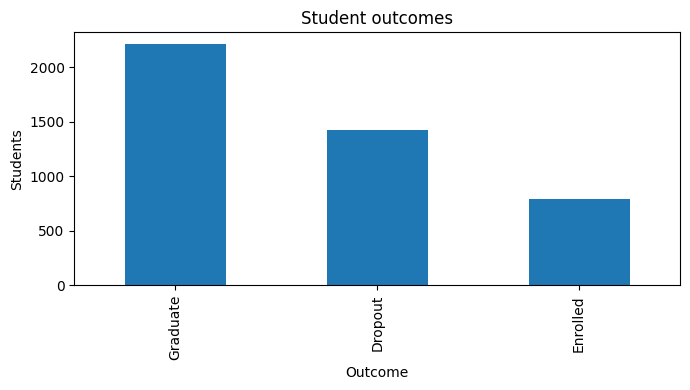

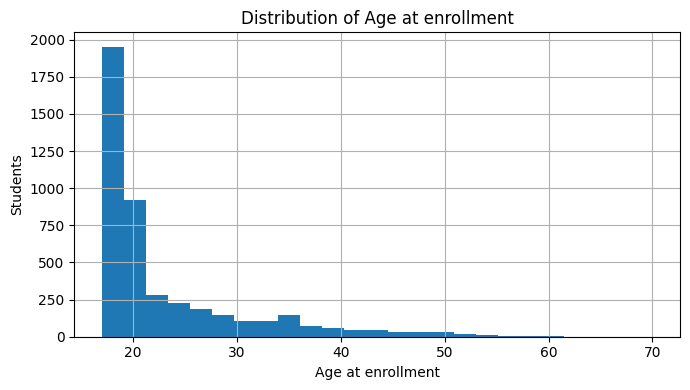

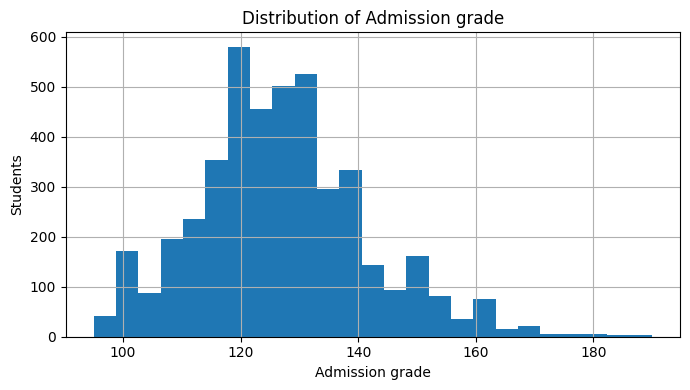

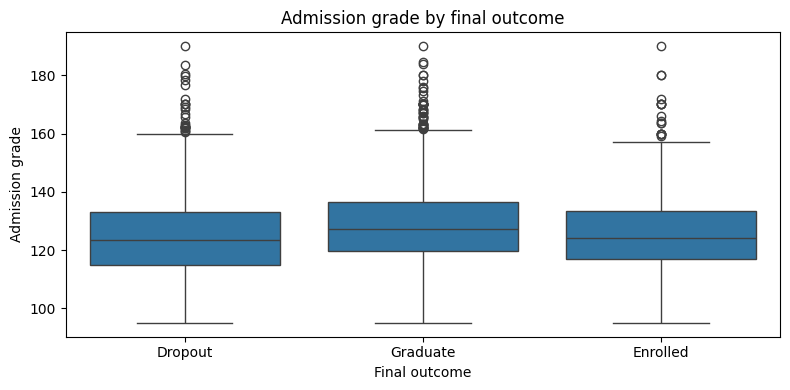

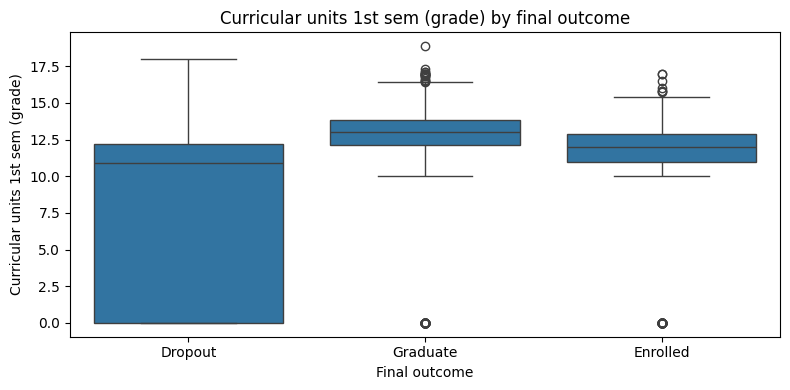

Target,Dropout,Enrolled,Graduate
Age group,,,
<=20,0.212,0.185,0.603
21-25,0.356,0.220,0.424
26-35,0.576,0.144,0.280
36+,0.531,0.120,0.349


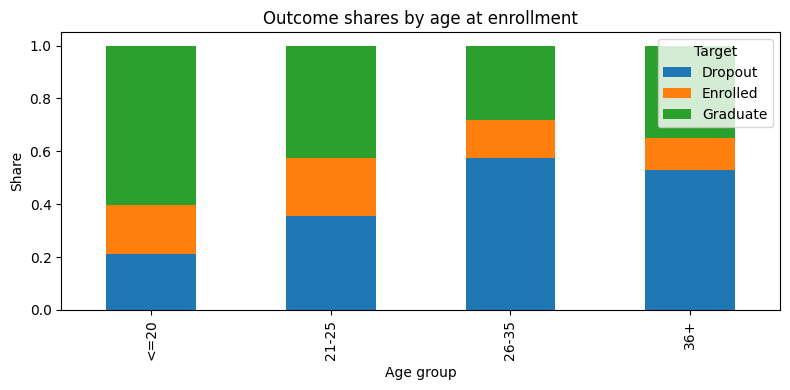

Selected numerical descriptive statistics by outcome:


Admission grade               Age at enrollment               \
                    mean median    std              mean median   std   
Target                                                                  
Dropout           124.96  123.6  15.13             26.07   23.0  8.70   
Enrolled          125.53  124.1  13.79             22.37   20.0  6.30   
Graduate          128.79  127.4  14.07             21.78   19.0  6.69   

         Curricular units 1st sem (grade)               
                                     mean median   std  
Target                                                  
Dropout                              7.26  10.93  6.03  
Enrolled                            11.13  12.00  3.68  
Graduate                            12.64  13.00  2.70

Kruskal-Wallis H=1094.1865, p=2.51434e-238, alpha=0.05; reject H0=True
Categorical columns: ['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance', 'Previous qualification', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International']
Numerical columns: ['Previous qualification (grade)', 'Admission grade', 'Age at enrollment', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Unemployment rate', 'Inflation rate', 'GDP']
Test accuracy: 0.6994
              precision    recall  f1-score   support

     Dropout       0.78      0.68      0.73       284
    Enrolled       0.38  

,precision,recall,f1-score,support
Dropout,0.781377,0.679577,0.726930,284.000000
Enrolled,0.383621,0.559748,0.455243,159.000000
Graduate,0.830049,0.762443,0.794811,442.000000
accuracy,0.699435,0.699435,0.699435,0.699435
macro avg,0.665015,0.667256,0.658995,885.000000
weighted avg,0.734224,0.699435,0.712021,885.000000


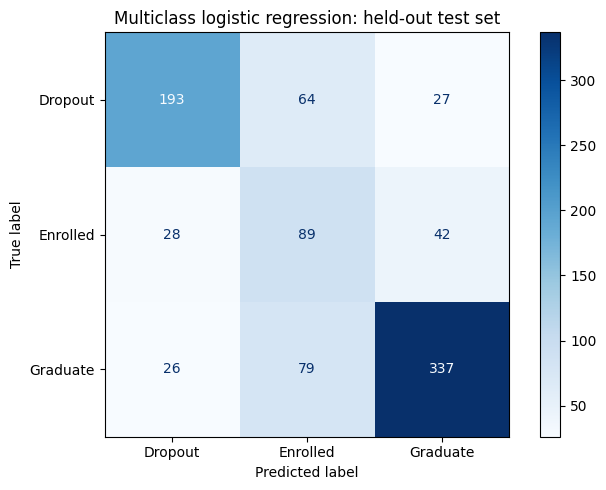

Largest coefficient magnitudes for Dropout [('num__Curricular units 1st sem (approved)', -1.825), ("cat__Mother's occupation_0", 1.424), ("cat__Mother's occupation_191", -1.2), ("cat__Father's occupation_90", 1.198), ('cat__Course_171', -1.144), ('cat__Application mode_15', -1.073), ('cat__Tuition fees up to date_0', 0.984), ('cat__Previous qualification_2', 0.907)]
Largest coefficient magnitudes for Enrolled [("cat__Mother's occupation_0", -1.639), ("cat__Mother's occupation_90", -1.377), ("cat__Father's qualification_39", 1.237), ("cat__Father's occupation_90", -1.133), ('cat__Course_9119', 1.042), ("cat__Mother's qualification_43", 0.906), ('cat__Application mode_10', -0.898), ("cat__Mother's qualification_9", -0.869)]
Largest coefficient magnitudes for Graduate [('num__Curricular units 1st sem (approved)', 2.17), ('cat__Application mode_15', 1.346), ('cat__Course_171', 1.326), ('num__Curricular units 1st sem (enrolled)', -1.064), ('cat__Course_9119', -1.013), ('cat__Marital status_

In [4]:
from scipy.stats import kruskal
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay
D=pd.read_csv(DATA,sep=';',encoding='utf-8-sig');D.columns=D.columns.str.strip().str.replace('\t','',regex=False)
print('Shape:',D.shape);display(D.head());print('Dtypes:');display(D.dtypes.value_counts());print('Missing:',int(D.isna().sum().sum()),'Duplicates:',int(D.duplicated().sum()));print('Target classes:',D['Target'].unique())
print('Outcome counts and percentages:');display(pd.concat([D.Target.value_counts(),D.Target.value_counts(normalize=True).mul(100).round(2)],axis=1,keys=['Count','Percent']))
fig,ax=plt.subplots(figsize=(7,4));D.Target.value_counts().plot.bar(ax=ax);ax.set(title='Student outcomes',xlabel='Outcome',ylabel='Students');plt.tight_layout();plt.savefig('target.png');plt.show()
for col in ['Age at enrollment','Admission grade']:
 fig,ax=plt.subplots(figsize=(7,4));D[col].hist(bins=25,ax=ax);ax.set(title=f'Distribution of {col}',xlabel=col,ylabel='Students');plt.tight_layout();plt.savefig(col.replace(' ','_')+'.png');plt.show()
for col,file in [('Admission grade','admission_box.png'),('Curricular units 1st sem (grade)','semester_box.png')]:
 fig,ax=plt.subplots(figsize=(8,4));sns.boxplot(data=D,x='Target',y=col,ax=ax);ax.set(title=f'{col} by final outcome',xlabel='Final outcome',ylabel=col);plt.tight_layout();plt.savefig(file);plt.show()
D['Age group']=pd.cut(D['Age at enrollment'],bins=[0,20,25,35,120],labels=['<=20','21-25','26-35','36+'])
age_table=pd.crosstab(D['Age group'],D.Target,normalize='index');display(age_table.round(3));ax=age_table.plot.bar(stacked=True,figsize=(8,4));ax.set(title='Outcome shares by age at enrollment',xlabel='Age group',ylabel='Share');plt.tight_layout();plt.savefig('age_outcome.png');plt.show()
print('Selected numerical descriptive statistics by outcome:');display(D.groupby('Target')[['Admission grade','Age at enrollment','Curricular units 1st sem (grade)']].agg(['mean','median','std']).round(2))
# Kruskal-Wallis is robust to non-normal grade distributions; independence is assumed.
groups=[g['Curricular units 1st sem (grade)'].dropna().values for _,g in D.groupby('Target')]
stat,p=kruskal(*groups);print(f'Kruskal-Wallis H={stat:.4f}, p={p:.6g}, alpha=0.05; reject H0={p<0.05}')
# Exclude second-semester variables to simulate an end-of-first-semester prediction.
X=D.drop(columns=['Target','Age group']+[c for c in D.columns if '2nd sem' in c]);y=D.Target
# Integer-coded categories are not continuous measurements.
cat_keywords=['Marital status','Application mode','Application order','Course','Daytime/evening attendance','Previous qualification','Nacionality',"Mother's qualification","Father's qualification","Mother's occupation","Father's occupation",'Displaced','Educational special needs','Debtor','Tuition fees up to date','Gender','Scholarship holder','International']
cat=[c for c in X if any(c==k for k in cat_keywords)];num=[c for c in X if c not in cat]
print('Categorical columns:',cat);print('Numerical columns:',num)
pre=ColumnTransformer([('cat',OneHotEncoder(handle_unknown='ignore'),cat),('num',StandardScaler(),num)])
model=Pipeline([('pre',pre),('lr',LogisticRegression(max_iter=2000,class_weight='balanced'))])
Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=.2,random_state=42,stratify=y)
model.fit(Xtr,ytr);pred=model.predict(Xte)
print('Test accuracy:',round(accuracy_score(yte,pred),4));print(classification_report(yte,pred,zero_division=0))
report=pd.DataFrame(classification_report(yte,pred,output_dict=True,zero_division=0)).T;display(report);report.to_csv('classification_results.csv')
fig,ax=plt.subplots(figsize=(7,5));ConfusionMatrixDisplay.from_predictions(yte,pred,ax=ax,cmap='Blues');ax.set(title='Multiclass logistic regression: held-out test set');plt.tight_layout();plt.savefig('confusion.png');plt.show()
feature_names=model.named_steps['pre'].get_feature_names_out();coeff=model.named_steps['lr'].coef_
for cls,co in zip(model.named_steps['lr'].classes_,coeff):
 top=np.argsort(abs(co))[-8:][::-1];print('Largest coefficient magnitudes for',cls,[(feature_names[i],round(float(co[i]),3)) for i in top])
print('Interpretation: Coefficients are conditional associations, not causal effects. Recommendations: investigate academic tutoring for weak first-semester results, proactive financial-support outreach, and opt-in advising for older entrants. Limitations: observational data, proxy/fairness risks, and imperfect early-prediction timing. Never use scores to deny opportunities; audit performance by groups and use human review.')
